# C1 · The Pulse Sequence

**Part:** C – The MRI experiment · **Reading time:** ~40 min · **Pass 1 overview:** [From signal to image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · **Refreshers you may want:** [Fourier pairs and sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb) (sinc pulses), [Magnetism from currents](../refreshers/RP1_Magnetism_from_Currents.ipynb) (gradient coils)

Magnetic resonance experiments are described by a **pulse sequence**: a timing diagram that shows how the different magnetic fields (RF, gradients) are switched and when the signal is recorded. A pulse-sequence diagram is the "sheet music" the scanner plays: it encodes the image contrast, the type of spatial encoding and the imaging speed. This chapter explains how to read one line by line, defines TE, TR and the flip angle, and draws a realistic 2D gradient-echo sequence in Python from physical specifications—including the hardware limits that set its timing.

## Learning goals

1. Understand what MRI is measuring
    * Identify when signals are measured during an MRI experiment
1. Describe how various types of MRI contrast are created
    * Understand what is shown in a pulse sequence diagram (RF, $G_z$, $G_y$, $G_x$, ADC)
    * Define flip angle, TE, TR, $N_{TR}$, $T_{read}$, $T_{active}$
1. Describe how images are formed
    * Understand that a pulse sequence must be repeated to form an image, and compute the scan time
1. Relate sequence timings to hardware limits (gradient amplitude and slew rate, RF power and SAR, receiver bandwidth)

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $t$ | time | s | |
| $B_0$, $f_0=\bar\gamma B_0$ | main field; Larmor frequency | T; Hz | 3 T, 127.7 MHz |
| $\bar\gamma$, $\gamma$ | gyromagnetic ratio | Hz/T; rad s⁻¹ T⁻¹ | 42.58 MHz/T |
| $b_1(t)$, $B_1$ | RF envelope; RF amplitude | T | 1–25 µT |
| $\theta$ | flip angle | rad or ° | 5–180° |
| $T_{rf}$, $BW_{rf}$, $TBW$ | RF pulse duration, bandwidth, time–bandwidth product | s, Hz, – | 2 ms, 2 kHz, 4 |
| $G_x,G_y,G_z$ | gradient amplitudes along $x$ (readout), $y$ (phase encode), $z$ (slice select) | T/m | up to 40–80 mT/m |
| $G_{max}$, $SR$ | maximum gradient amplitude; slew rate (max $dG/dt$) | T/m; T/m/s | 40 mT/m; 150 T/m/s |
| $G_{z,SS}$, $\Delta z$ | slice-select gradient; slice thickness | T/m; m | 5 mm |
| $G_{x,r}$ | readout gradient amplitude | T/m | |
| $G_{y,PE}$ | maximum phase-encode gradient | T/m | |
| $\vec k(t)=\bar\gamma\int_0^t\vec G(\tau)d\tau$ | k-space position (accumulated gradient area × $\bar\gamma$) | m⁻¹ | defined fully in [C2](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb) |
| $FOV$, $N_{read}$, $N_{PE}$ | field of view; number of readout samples; number of phase encodes | m; – | 0.256 m; 256 |
| $\Delta t$, $BW_{read}=1/\Delta t$ | ADC dwell time; receiver bandwidth | s; Hz | 15.6 µs; 64 kHz |
| $T_{read}=N_{read}\Delta t$ | readout duration | s | ms |
| $TE$, $TR$ | echo time; repetition time | s | ms–s |
| $N_{TR}$ | number of repetitions | – | |
| $T_{active}$ | time per TR in which RF/gradients are on (sets min. TR) | s | |
| $NEX$ | number of averages | – | |
| $T_{scan}=TR\cdot N_{TR}\cdot NEX$ | scan time | s | |
| $SAR$ | specific absorption rate | W/kg | ≤ 2 W/kg (whole body, normal mode) |
| $T_1$ | longitudinal relaxation time constant | s | |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1 Components of a pulse sequence

All MRI experiments can be defined by their pulse sequence. It describes all manipulations the scanner performs, including their relative timings and amplitudes. Every experiment follows the same cycle:

1. **Polarization** – the patient sits in $B_0$; $\vec M$ builds up along $z$ ($T_1$ recovery; [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb)). Always present, never drawn.
2. **Excitation** – an RF pulse tips $\vec M$ by the flip angle $\theta$, creating transverse magnetization ([A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb)).
3. **Encoding and acquisition** – gradients give the transverse magnetization a position-dependent phase while the receiver samples the signal.
4. **Repeat** – after a time TR, the block is played again with a different gradient pattern, until enough data for an image is collected. Between repetitions $M_z$ partially recovers.

### 1.1 RF excitation pulse (RF)

The RF excitation pulse is the first required component: it rotates or flips the magnetization into the transverse plane, creating precessing magnetization that can actually be measured.

![RF pulse](../images/pulse_sequence-RF.png)

*An RF pulse as drawn in a sequence diagram: the envelope $b_1(t)$ (here a sinc shape).*

![Idealized RF pulse](../images/pulse_sequence-RF_ideal.png)

*Idealized RF pulse symbol: an arrow or box labelled with the flip angle, used when the pulse shape doesn't matter.*

Note that the RF line shows only the **envelope**. The pulse is actually applied at a very high carrier frequency near the Larmor frequency (127.7 MHz at 3 T); the diagram is drawn in the rotating frame ([A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb)). The plot below shows the difference with a toy carrier of 10 kHz (a real one would be 10 000× faster).

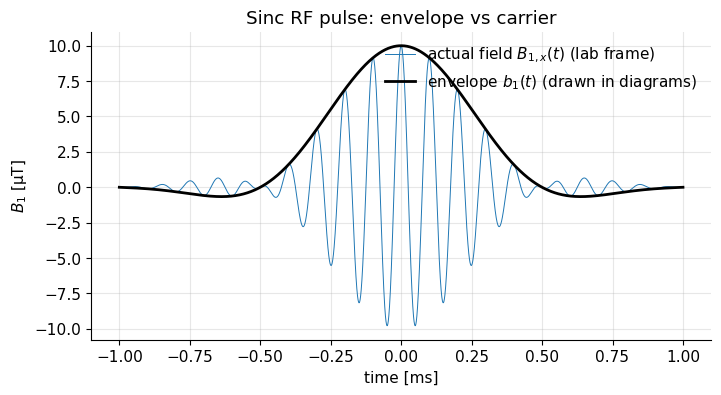

In [2]:
# RF envelope (what the diagram shows) vs the actual oscillating field (toy carrier 10 kHz)
T_rf = 2e-3; t = np.linspace(-T_rf/2, T_rf/2, 4000)
TBW = 4
envelope = np.sinc(TBW * t / T_rf) * (0.54 + 0.46*np.cos(2*np.pi*t/T_rf))   # Hamming-windowed sinc, 2 zero crossings each side
B1_peak = 10e-6                                                             # T
carrier = 10e3                                                              # Hz (toy; real: f0 = 127.7 MHz)
plt.plot(t*1e3, B1_peak*envelope*np.cos(2*np.pi*carrier*t)*1e6, lw=0.7, label=r"actual field $B_{1,x}(t)$ (lab frame)")
plt.plot(t*1e3, B1_peak*envelope*1e6, "k", lw=2, label=r"envelope $b_1(t)$ (drawn in diagrams)")
plt.xlabel("time [ms]"); plt.ylabel(r"$B_1$ [µT]"); plt.legend(loc="upper right"); plt.title("Sinc RF pulse: envelope vs carrier"); plt.show()

Interpretation: the diagram's smooth sinc is the slowly varying amplitude of a field that, in reality, oscillates ~250 000 times during a 2 ms pulse at 3 T.

### 1.2 Magnetic field gradients for localization ($G_X$, $G_Y$, $G_Z$)

The **gradients** are extra fields that make $B_z$ vary linearly with position, $B_z=B_0+G_xx+G_yy+G_zz$ [T], so that the precession frequency depends on position. They are also used in a pulsed fashion: switched on and off during the sequence. This is done primarily for spatial localization—RF slice selection and spatial encoding, described in [E2](../pass2_deep_dive/E2_Slice_Selection.ipynb) and [F1](../pass2_deep_dive/F1_Spatial_Encoding.ipynb). Importantly, multiple measurements with slightly different gradient pulses must typically be used to get enough data to form an image.

![Gradient](../images/pulse_sequence-gradients.png)

*Gradient waveforms are drawn as trapezoids: ramp up, flat top, ramp down. What matters physically is mostly their **area** (amplitude × time).*

### 1.3 Data acquisition window (DAQ / ADC)

The data acquisition window (DAQ, also called ADC for analog-to-digital converter) indicates when signals are measured and recorded from the RF receive coils. This must happen after excitation and is done together with gradients to perform spatial encoding. Remember that it is the **transverse** magnetization ($M_{XY}$) that is measured—$M_z$ produces no signal.

![DAQ](../images/pulse_sequence-DAQ.png)

*The ADC window: during this time the receiver samples the signal $N_{read}$ times, once every dwell time $\Delta t$.*

## 2 Pulse sequence diagrams

The pulse-sequence diagram conveys a significant amount of information about an MRI method: the expected image contrast, the type of spatial encoding, the overall imaging speed and more.

### 2.1 Sample pulse sequence diagram, line by line

The diagram has one line ("axis") per component—RF; gradients in $X$, $Y$, $Z$; data acquisition—showing their behaviour over time. A single "block" of the sequence is usually shown, but it is repeated many times.

![Pulse sequence diagram](../images/pulse_sequence-diagram.png)

Reading it from top to bottom (for this 2D gradient-echo sequence):

* **RF:** one sinc-shaped excitation pulse with flip angle $\theta$. Its centre defines $t=0$ for the echo time.
* **$G_Z$ (slice select):** a trapezoid played *during* the RF pulse makes the resonance frequency depend on $z$, so the RF only excites one slice ([E2](../pass2_deep_dive/E2_Slice_Selection.ipynb)). The following negative lobe (the **slice rephaser**, half the area of the part after the RF centre) undoes the phase spread across the slice thickness. A later positive lobe is a **spoiler**, which dephases leftover transverse magnetization before the next TR.
* **$G_X$ (readout/frequency encoding):** a negative **prephaser** lobe, then a long positive **readout** lobe during the ADC. The prephaser moves the encoding to $-k_{max}$; the readout sweeps through k-space and the **gradient echo** forms when the accumulated area returns to zero—at the centre of the ADC window ([F1](../pass2_deep_dive/F1_Spatial_Encoding.ipynb), [D3](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb)).
* **$G_Y$ (phase encoding):** a lobe drawn as a "ladder" of stacked lines: its amplitude is different in every repetition (one step per line of k-space). After the readout, an opposite lobe (**rewinder**) undoes it.
* **DAQ/ADC:** the receiver is on while the readout gradient is flat.

### 2.2 Annotations

In almost every MRI experiment the basic block is repeated, but with a different gradient pattern to perform the necessary spatial encoding. This is typically annotated in two ways: (1) the changing gradient is drawn as multiple lines on its axis (the phase-encode ladder); (2) brackets around the block with the number of repetitions.

![Annotated pulse sequence diagram](../images/pulse_sequence-diagram-annotated.png)

### 2.3 Simplified diagrams

For analysing image contrast and relaxation it is often helpful to use a simplified diagram with only RF pulses and data acquisition windows. Sometimes simplified gradients are added (e.g. **crushers**, gradients that purposely destroy transverse magnetization).

Diagrams are also often drawn with idealized rectangular gradients, as if they could change instantaneously. In reality there is a minimum time needed to change a gradient, set by the **slew rate**, which turns the rectangles into trapezoids.

![Simplified pulse sequence diagram](../images/pulse_sequence-diagram-simple.png)

## 3 Key parameters

The following key parameters are typically defined on a pulse-sequence diagram:

* **Flip angle** ($\theta$) – how much an RF pulse flips (rotates, tips) the net magnetization; $\theta=\gamma\int|b_1(t)|dt$ ([A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb)).
* **Echo time** (TE) – the time between excitation and the echo, typically measured from the centre of the RF excitation pulse to the centre of the data acquisition window (where k-space centre is sampled).
* **Repetition time** (TR) – the time between successive repetitions of the main sequence block (e.g. RF centre to RF centre).
* **Number of repetitions** ($N_{TR}$) – how many times the block must be repeated (e.g. $N_{PE}$ phase-encode steps × slices or averages).
* **Readout time** ($T_{read}$) – the time the data acquisition window is open within one repetition, $T_{read}=N_{read}\Delta t$.
* **Active time** ($T_{active}$) – the time required for all RF pulses and gradients within one repetition. This determines the minimum TR.

![Pulse sequence diagram with all parameters](../images/pulse_sequence-diagram-all.png)

The total acquisition time follows directly:

$$T_{scan}=TR\cdot N_{TR}\cdot NEX$$

In words: the scan time is the repetition time multiplied by the number of repetitions needed (and by the number of averages).

where $NEX$ is the number of averages. Example: a $T_1$-weighted spin echo with TR = 500 ms and 256 phase encodes takes 128 s; a gradient echo with TR = 10 ms, 2.6 s per slice. TE and TR also set the contrast ([D1](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb)): with TR ≪ 5 $T_1$, $M_z$ does not fully recover between excitations (partial saturation → $T_1$ weighting); long TE lets $T_2$/$T_2^*$ differences develop.

## 4 Drawing a 2D gradient-echo sequence from physics

We now construct the diagram above numerically from imaging specifications, using minimum-duration trapezoids limited by $G_{max}=40$ mT/m and $SR=150$ T/m/s. The required gradient *areas* come from k-space ([C2](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb), [F2](../pass2_deep_dive/F2_K-space.ipynb)):

* slice select: $G_{z,SS}=BW_{rf}/(\bar\gamma\Delta z)$ with $BW_{rf}=TBW/T_{rf}$;
* readout: $G_{x,r}=BW_{read}/(\bar\gamma\,FOV)$, duration $T_{read}=N_{read}/BW_{read}$;
* phase encode: area up to $k_{max}/\bar\gamma$ with $k_{max}=N_{PE}/(2FOV)$;
* prephasers/rephasers: minus half of the corresponding lobe area.

In [3]:
gb = mt.GAMMA_BAR
Gmax, SR = 40e-3, 150.0                    # T/m, T/m/s (scanner limits)

def trapezoid(area, Gmax=Gmax, SR=SR):
    """Shortest trapezoid (or triangle) with the given area [T s/m]. Returns (ramp, flat, amplitude)."""
    a, tr = abs(area), Gmax / SR
    if a <= Gmax * tr:                       # too small for a flat top: triangle
        tr = np.sqrt(a / SR)
        return tr, 0.0, np.sign(area) * SR * tr
    return tr, (a - Gmax*tr) / Gmax, np.sign(area) * Gmax

def trap_points(t0, ramp, flat, amp):
    """Corner points (t, G) of a trapezoid starting at t0."""
    return [t0, t0+ramp, t0+ramp+flat, t0+2*ramp+flat], [0, amp, amp, 0]

# ---- imaging specification ----
T_rf, TBW, dz = 2e-3, 4, 5e-3              # RF duration [s], time-bandwidth product, slice thickness [m]
FOV, N = 0.256, 256                        # field of view [m], matrix (readout and phase encode)
BW_read = 64e3                             # receiver bandwidth [Hz] -> dwell time 15.6 us

# slice selection
G_ss = (TBW / T_rf) / (gb * dz)                       # T/m
ramp_ss = G_ss / SR
# readout
G_r = BW_read / (gb * FOV); T_read = N / BW_read; ramp_r = G_r / SR
# prephasers / rephasers / phase encode (areas in T s/m)
A_ss_reph = -(G_ss*T_rf/2 + G_ss*ramp_ss/2)
A_r_pre = -(G_r*T_read/2 + G_r*ramp_r/2)
A_pe_max = (N / (2*FOV)) / gb
lobes = {name: trapezoid(A) for name, A in [("ss_reph", A_ss_reph), ("r_pre", A_r_pre), ("pe", A_pe_max)]}
T_lobe = max(2*r + f for r, f, _ in lobes.values())  # play all three simultaneously

# timeline (t = 0 at start of slice-select ramp)
t_rf0 = ramp_ss; t_rf_c = t_rf0 + T_rf/2; t_ss_end = 2*ramp_ss + T_rf
t_lobe = t_ss_end
t_ro = t_lobe + T_lobe                                 # readout ramp starts
t_adc0 = t_ro + ramp_r; t_adc1 = t_adc0 + T_read
TE = (t_adc0 + T_read/2) - t_rf_c
spoil = trapezoid(4 * G_r * T_read)                   # spoiler: several cycles of dephasing per voxel
t_spoil = t_adc1 + ramp_r
TR_min = t_spoil + 2*spoil[0] + spoil[1]
print(f"G_ss = {G_ss*1e3:.2f} mT/m, G_read = {G_r*1e3:.2f} mT/m, max PE lobe amplitude = {lobes['pe'][2]*1e3:.2f} mT/m")
print(f"dwell time = {1/BW_read*1e6:.1f} us, T_read = {T_read*1e3:.2f} ms, ramp time at full G = {Gmax/SR*1e3:.2f} ms")
print(f"minimum TE = {TE*1e3:.2f} ms, minimum TR (active time) = {TR_min*1e3:.2f} ms")

G_ss = 9.39 mT/m, G_read = 5.87 mT/m, max PE lobe amplitude = 40.00 mT/m
dwell time = 15.6 us, T_read = 4.00 ms, ramp time at full G = 0.27 ms
minimum TE = 3.66 ms, minimum TR (active time) = 9.38 ms


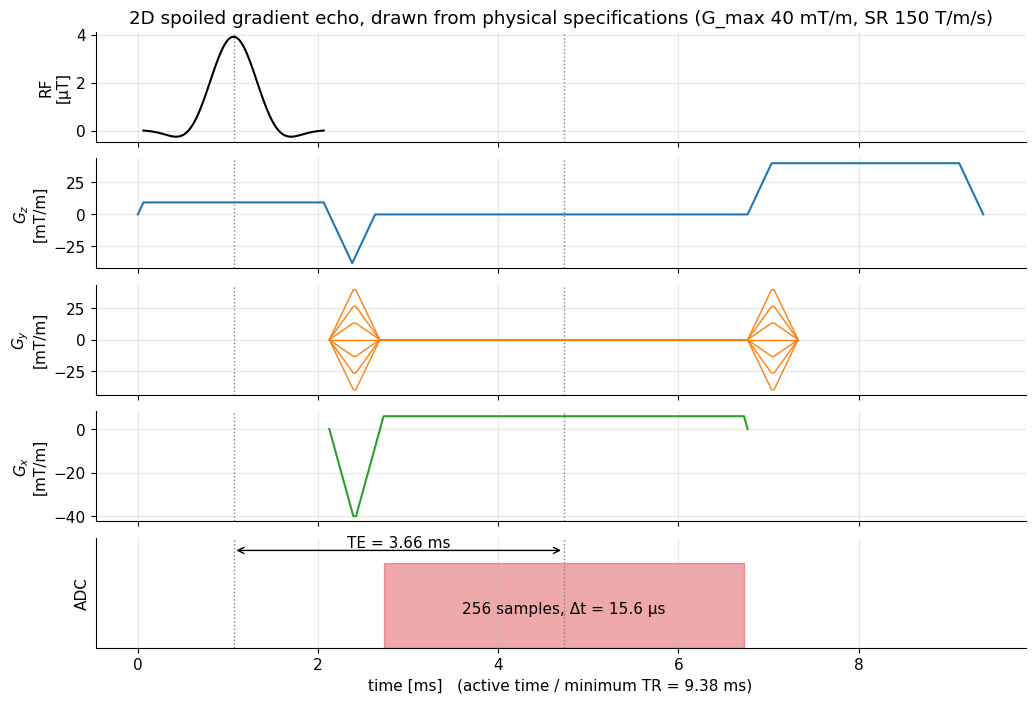

In [4]:
def draw_gre(n_pe_lines=7, show=True):
    fig, ax = plt.subplots(5, 1, figsize=(12, 8), sharex=True, gridspec_kw=dict(hspace=0.15))
    ms = 1e3
    # RF
    t = np.linspace(t_rf0, t_rf0 + T_rf, 400); tc = t - t_rf_c
    env = np.sinc(TBW*tc/T_rf) * (0.54 + 0.46*np.cos(2*np.pi*tc/T_rf))
    B1 = mt.b1_for_flip(np.deg2rad(30), T_rf) / np.mean(env)       # 30-degree pulse
    ax[0].plot(t*ms, B1*env*1e6, "k"); ax[0].set_ylabel("RF\n[µT]")
    # Gz: slice select, rephaser, spoiler
    tz, gz = trap_points(0, ramp_ss, T_rf, G_ss)
    tz2, gz2 = trap_points(t_lobe, *lobes["ss_reph"]); tz3, gz3 = trap_points(t_spoil, *spoil)
    ax[1].plot(np.r_[tz, tz2, tz3]*ms, np.r_[gz, gz2, gz3]*1e3, "C0"); ax[1].set_ylabel("$G_z$\n[mT/m]")
    # Gy: phase-encode ladder and rewinder
    for s in np.linspace(-1, 1, n_pe_lines):
        ty, gy = trap_points(t_lobe, *lobes["pe"]); ty2, gy2 = trap_points(t_spoil, *lobes["pe"])
        ax[2].plot(np.r_[ty, ty2]*ms, np.r_[np.array(gy)*s, -np.array(gy2)*s]*1e3, "C1", lw=1)
    ax[2].set_ylabel("$G_y$\n[mT/m]")
    # Gx: prephaser + readout
    tx, gx = trap_points(t_lobe, *lobes["r_pre"]); tx2, gx2 = trap_points(t_ro, ramp_r, T_read, G_r)
    ax[3].plot(np.r_[tx, tx2]*ms, np.r_[gx, gx2]*1e3, "C2"); ax[3].set_ylabel("$G_x$\n[mT/m]")
    # ADC
    ax[4].fill_between([t_adc0*ms, t_adc1*ms], 0, 1, color="C3", alpha=0.4); ax[4].set_ylim(0, 1.3)
    ax[4].set_ylabel("ADC"); ax[4].set_yticks([])
    for a in ax:
        a.axvline(t_rf_c*ms, color="gray", ls=":", lw=1); a.axvline((t_adc0 + T_read/2)*ms, color="gray", ls=":", lw=1)
    ax[4].annotate("", ((t_adc0+T_read/2)*ms, 1.15), (t_rf_c*ms, 1.15), arrowprops=dict(arrowstyle="<->"))
    ax[4].text((t_rf_c + TE/2)*ms, 1.18, f"TE = {TE*1e3:.2f} ms", ha="center")
    ax[4].text((t_adc0 + T_read/2)*ms, 0.4, f"{N} samples, Δt = {1e6/BW_read:.1f} µs", ha="center")
    ax[4].set_xlabel(f"time [ms]   (active time / minimum TR = {TR_min*1e3:.2f} ms)")
    ax[0].set_title("2D spoiled gradient echo, drawn from physical specifications (G_max 40 mT/m, SR 150 T/m/s)")
    if show: plt.show()
    return fig

draw_gre();

Interpretation: every element of the textbook diagram appears with real amplitudes and durations. The slice-select gradient (9.4 mT/m) is set by RF bandwidth and slice thickness; the readout (5.9 mT/m) by receiver bandwidth and FOV; the phase-encode lobes are short triangles/trapezoids near $G_{max}$. With these parameters the minimum TE is ≈ 4 ms and the minimum TR ≈ 9 ms—close to what a scanner's protocol card would offer.

The next plot shows *why* the echo is at the centre of the ADC: the accumulated readout-gradient area $k_x(t)=\bar\gamma\int_0^tG_x(\tau)d\tau$ (the k-space position, formally introduced in [C2](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb)).

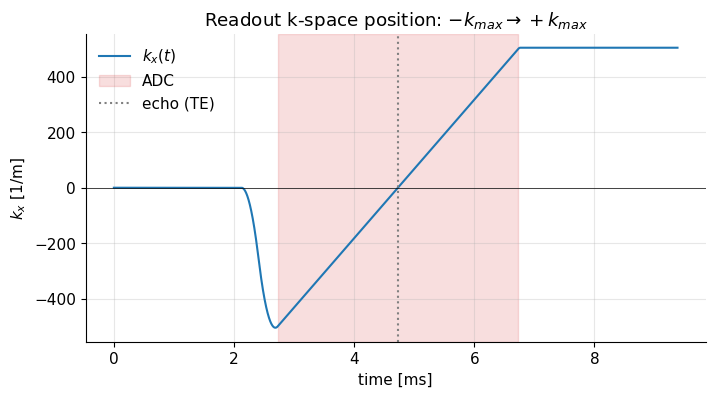

k_max = N/(2 FOV) = 500 1/m


In [5]:
# accumulated area of Gx -> k_x(t); the gradient echo occurs where k_x = 0
tt = np.linspace(0, TR_min, 20000)
tx, gx = trap_points(t_lobe, *lobes["r_pre"]); tx2, gx2 = trap_points(t_ro, ramp_r, T_read, G_r)
Gx_t = np.interp(tt, np.r_[0, tx, tx2, TR_min], np.r_[0, gx, gx2, 0])
kx = gb * np.cumsum(Gx_t) * (tt[1] - tt[0])           # 1/m
plt.plot(tt*1e3, kx, label=r"$k_x(t)$")
plt.axhline(0, color="k", lw=0.5); plt.axvspan(t_adc0*1e3, t_adc1*1e3, color="C3", alpha=0.15, label="ADC")
plt.axvline((t_adc0 + T_read/2)*1e3, color="gray", ls=":", label="echo (TE)")
plt.xlabel("time [ms]"); plt.ylabel(r"$k_x$ [1/m]"); plt.legend(); plt.title(r"Readout k-space position: $-k_{max}\to+k_{max}$"); plt.show()
print(f"k_max = N/(2 FOV) = {N/(2*FOV):.0f} 1/m")

Interpretation: the prephaser drives $k_x$ to $-k_{max}=-500$ m⁻¹; during the ADC window it rises linearly to $+k_{max}$ and passes through zero exactly at TE—that's the gradient echo. Each TR does this with a different $k_y$ set by the phase-encode step.

> **TODO (polish):** add a small ipywidgets explorer (FOV, N, BW, slice thickness → TE/TR) and a spin-echo variant of the drawing.

> **🔧 Engineering reality: what limits the timings?**
> * **Gradient amplitude and slew rate.** A clinical gradient reaches 40–80 mT/m with slew rates of 100–200 T/m/s, so ramping to full amplitude takes $G_{max}/SR\approx0.2$–0.4 ms. Higher slew rates are possible electrically but are limited by **peripheral nerve stimulation** (PNS, from the induced $dB/dt$) and by gradient heating/duty cycle and acoustic noise ([B4](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb)).
> * **RF duration and amplitude.** Peak $B_1$ is limited (~15–25 µT for body coils) by the RF amplifier. A 90° hard pulse at 15 µT needs ≥ 0.39 ms; selective sinc pulses need several times more. Shorter pulses mean higher bandwidth (thinner slices with less gradient) but higher peak power.
> * **SAR.** The RF energy deposited scales ∝ $B_1^2$ ∝ $\theta^2/T_{rf}$ per pulse and ∝ $B_0^2$; per TR it is limited to 2 W/kg whole-body (normal mode). Many 180° pulses at short TR (fast spin echo at 3 T) quickly hit this limit ([B6](../pass2_deep_dive/B6_MRI_Safety.ipynb)).
> * **ADC bandwidth.** The receiver bandwidth $BW_{read}=1/\Delta t$ sets $T_{read}$ and the readout gradient. High bandwidth shortens TE/TR and reduces chemical-shift and off-resonance distortion, but SNR ∝ $1/\sqrt{BW_{read}}$ ([G2](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb)). Modern digital receivers support dwell times down to ~1 µs.

In [6]:
# Quick numbers for the engineering box
for B1max in [15e-6, 25e-6]:
    print(f"B1max = {B1max*1e6:.0f} uT: shortest 90-deg hard pulse = {np.pi/2/(mt.GAMMA*B1max)*1e3:.2f} ms, "
          f"180-deg = {np.pi/(mt.GAMMA*B1max)*1e3:.2f} ms")
for G, S in [(40e-3, 150), (80e-3, 200)]:
    print(f"Gmax = {G*1e3:.0f} mT/m, SR = {S} T/m/s: rise time = {G/S*1e3:.2f} ms")
print("relative SAR per pulse ~ theta^2 / T_rf:  180 deg vs 90 deg (same T_rf) =", (180/90)**2)

B1max = 15 uT: shortest 90-deg hard pulse = 0.39 ms, 180-deg = 0.78 ms
B1max = 25 uT: shortest 90-deg hard pulse = 0.23 ms, 180-deg = 0.47 ms
Gmax = 40 mT/m, SR = 150 T/m/s: rise time = 0.27 ms
Gmax = 80 mT/m, SR = 200 T/m/s: rise time = 0.40 ms
relative SAR per pulse ~ theta^2 / T_rf:  180 deg vs 90 deg (same T_rf) = 4.0


## Key takeaways

* A pulse sequence is a timing diagram with one line each for RF, $G_z$ (slice select), $G_y$ (phase encode), $G_x$ (readout) and ADC; one block is drawn and repeated $N_{TR}$ times.
* The RF line shows the envelope $b_1(t)$ in the rotating frame; the real field oscillates at $f_0$.
* Gradients matter through their areas: rephasers and prephasers are half-area lobes; the gradient echo forms where the accumulated area returns to zero.
* TE = RF centre → echo centre; TR = time between repetitions; flip angle θ = γ∫|b₁|dt; $T_{scan}=TR\cdot N_{TR}\cdot NEX$.
* Minimum TE/TR follow from the imaging specs (slice thickness, FOV, matrix, bandwidth) combined with hardware limits ($G_{max}$, slew rate, peak $B_1$, SAR, ADC).

## Check your understanding

1. In the diagram, why is the slice-select rephasing lobe only about half the area of the slice-select gradient?

<details><summary>Answer</summary>

The magnetization is (approximately) created at the centre of the RF pulse. Only the gradient area *after* the centre (half the flat top plus the ramp-down) dephases it, so only that area must be undone.

</details>

2. A sequence has TR = 8 ms, 256 phase encodes, 2 averages. How long does it take? What if TR = 600 ms?

<details><summary>Answer</summary>

$8\,\text{ms}\times256\times2=4.1$ s; $600\,\text{ms}\times256\times2=307$ s ≈ 5 min.

</details>

3. You halve the receiver bandwidth from 64 to 32 kHz with the same FOV and matrix. What happens to $T_{read}$, $G_{x,r}$, the minimum TE and the SNR?

<details><summary>Answer</summary>

$T_{read}$ doubles (4 → 8 ms), $G_{x,r}$ halves, the minimum TE increases by about 2 ms (half the extra readout plus a longer prephaser), SNR increases by $\sqrt2$.

</details>

4. Why can't the gradients be switched instantaneously, and what does that do to the drawing?

<details><summary>Answer</summary>

The gradient coil has inductance and the amplifier has finite voltage, and fast $dB/dt$ stimulates nerves; the slew rate is therefore limited (e.g. 150 T/m/s), turning ideal rectangles into trapezoids with ramps of ~0.1–0.4 ms.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Pulse Sequence". Changes: line-by-line reading of the diagram, the polarization–excitation–acquisition–repeat cycle, scan-time formula, envelope vs carrier plot, a 2D gradient-echo diagram computed from physical specifications with minimum TE/TR, $k_x(t)$ echo plot, and an engineering box on timing limits; typos corrected ("drawn to not show" → "do not show").*